# Librerías

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from urllib.request import urlopen
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Conjunto de datos

Total imágenes: 7


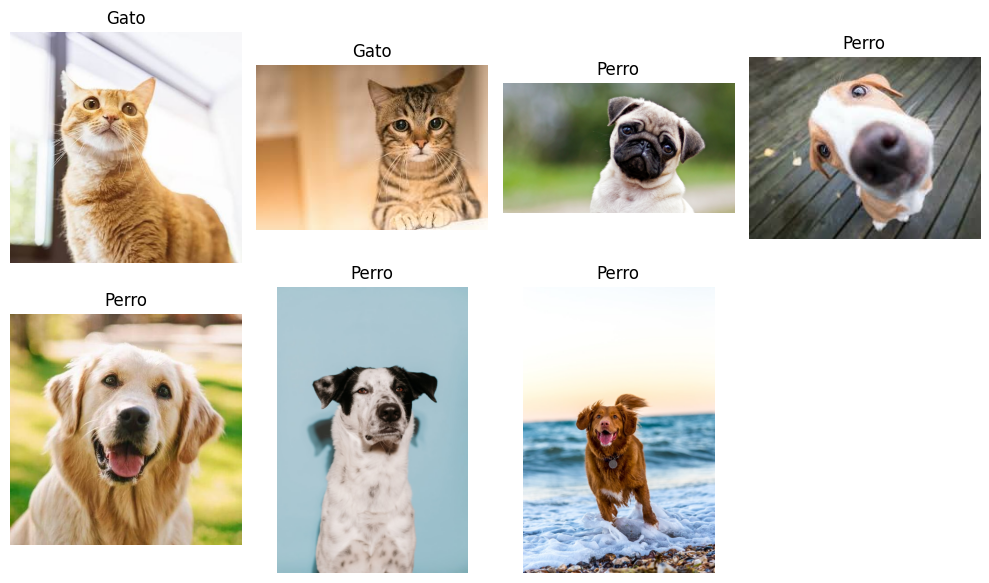

In [ ]:
np.random.seed(42)

# (puede cambiar/añadir)
gatos = [
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRubDxRqTjX0nhOeyDHbXm3YOY2HB__z3nSWMJNSWIQ5VnHQxHZYXetDJuE&s=10",
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS8t5Qv9hoArKjwgA25zZgoNoKuhbVU2zc6-A&s",


]

perros = [
    "https://c.files.bbci.co.uk/48DD/production/_107435681_perro1.jpg",
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRN4HJhnJo07reTM0Lta1HoTollHloqsqRUVw&s",
    "https://www.purina.es/sites/default/files/styles/ttt_image_510/public/2024-02/sitesdefaultfilesstylessquare_medium_440x440public2022-09golden20retriever.jpg?itok=48StbVfe",
    "https://plus.unsplash.com/premium_photo-1676389281733-aaefab0e7907?ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D&auto=format&fit=crop&q=80&w=686",
    "https://images.unsplash.com/photo-1530281700549-e82e7bf110d6?q=80&w=688&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D"

]

labels = []
images_rgb = []

# Descarga a RGB/Gray
for url in gatos + perros:
    img_bytes = urlopen(url).read()
    img_bgr = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    images_rgb.append(img_rgb)
    labels.append("Gato" if url in gatos else "Perro")

print("Total imágenes:", len(images_rgb))
plt.figure(figsize=(10,6))

for i in range(len(images_rgb)):
    plt.subplot(2, 4, i+1)
    plt.imshow(images_rgb[i])
    plt.title(labels[i])
    plt.axis('off')

plt.tight_layout(); plt.show()

# Extracción de características

Keypoints por imagen: [6618, 350, 930, 341, 398, 619]


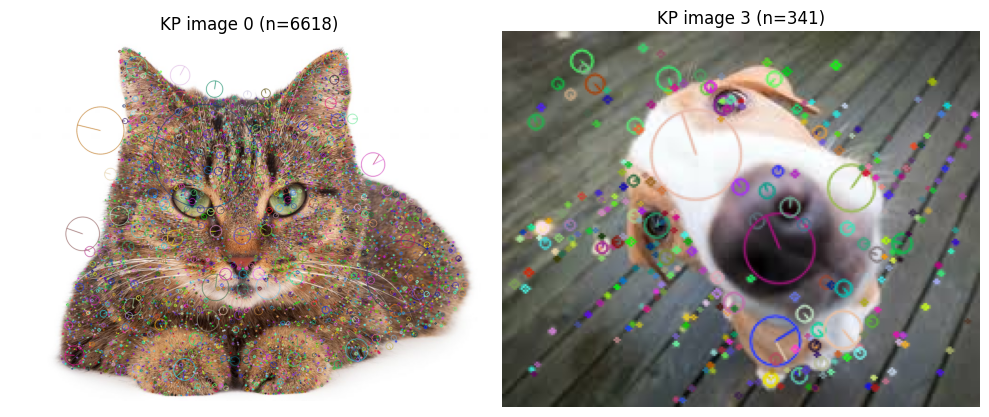

In [ ]:
sift = cv2.SIFT_create()

images_gray = []
all_desc_list = []   # Descriptores
n_keypoints = []

for img_rgb in images_rgb:
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    images_gray.append(gray)
    keypoints, descriptors = sift.detectAndCompute(gray, None) # Detecta puntos y calcula descriptores (SIFT = 128D por keypoint)

    if descriptors is None:
        descriptors = np.zeros((0, 128), dtype=np.float32)

    all_desc_list.append(descriptors)
    n_keypoints.append(len(keypoints))

print("Keypoints por imagen:", n_keypoints)


plt.figure(figsize=(10,5)) # Dónde aparece SIFT

for i, idx in enumerate([0, len(images_rgb)//2]):

    img_kp = cv2.drawKeypoints(images_rgb[idx], sift.detect(images_gray[idx], None), None,
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.subplot(1,2,i+1); plt.imshow(img_kp); plt.title(f"KP image {idx} (n={n_keypoints[idx]})"); plt.axis('off')

plt.tight_layout(); plt.show()


# Construcción de diccionario/vocabulario

In [ ]:

desc_stack = [] # Apila descriptores de todas las imágenes en una sola matriz para k-means

for desc in all_desc_list:

    if len(desc) > 400: #  muestreo (máx 400 por imagen)
        idx = np.random.choice(len(desc), 400, replace=False)
        desc = desc[idx]
    desc_stack.append(desc)

if len(desc_stack) == 0:
    raise RuntimeError("No hay descriptores; revisa que SIFT detecte puntos (más imágenes o mayor detalle).")

desc_stack = np.vstack(desc_stack).astype(np.float32)
print("Descriptores totales para k-means:", desc_stack.shape)


K = 120 # Tamaño del vocabulario (ajústalo y experimenta)

kmeans = MiniBatchKMeans(n_clusters=K, random_state=42, batch_size=2048, n_init="auto") # MiniBatchKMeans es más rápido y estable que KMeans para muchos puntos
kmeans.fit(desc_stack)

centers = kmeans.cluster_centers_
print("Diccionario visual entrenado. Centros shape:", centers.shape)


Descriptores totales para k-means: (2289, 128)
Diccionario visual entrenado. Centros shape: (80, 128)


# Cuantificación vectorial

X (BoVW): (6, 80)  y: (6,)   (K = 80 )


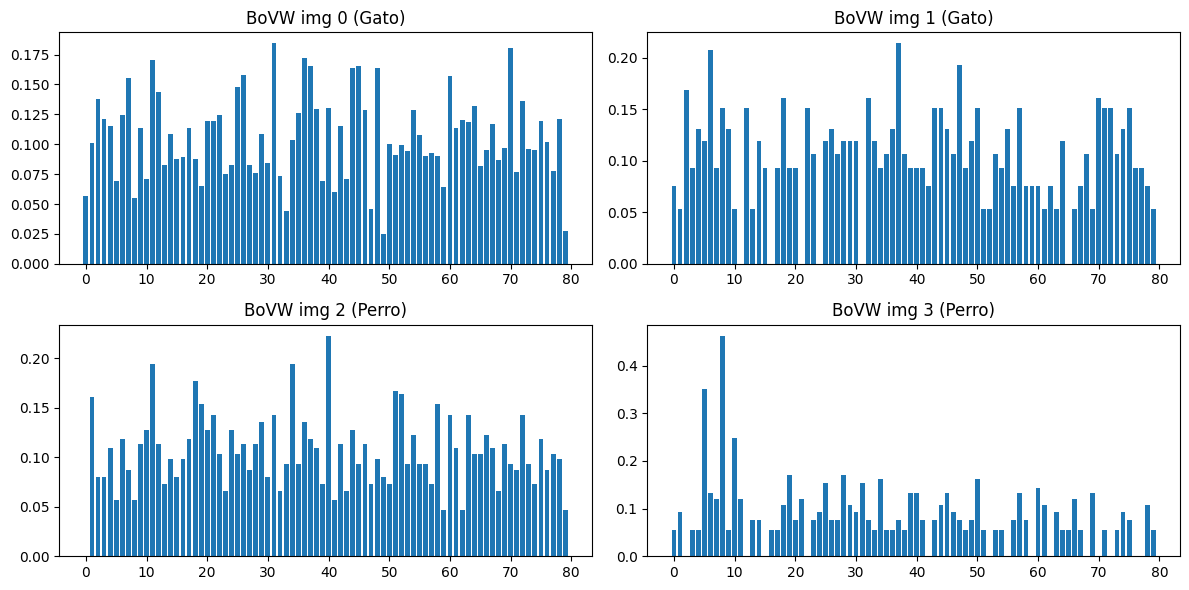

In [ ]:
bovw_list = [] # # Codifica cada imagen como histograma BoVW

for i, desc in enumerate(all_desc_list):
    if len(desc) == 0:

        hist = np.zeros(K, dtype=np.float32)
    else:
        # Asignación dura (hard assignment): cada descriptor -> centro más cercano
        # predict() devuelve el índice del cluster para cada descriptor
        word_ids = kmeans.predict(desc)               # shape: (num_desc,)
        hist = np.bincount(word_ids, minlength=K)     # cuentas por palabra visual (0..K-1)
        hist = hist.astype(np.float32)

    # Normalización recomendada (power-law + L2)
    hist = np.sqrt(hist)
    norm = np.linalg.norm(hist) + 1e-8
    hist = hist / norm

    bovw_list.append(hist)

X = np.vstack(bovw_list)             # shape: (num_imagenes, K)
y = np.array(labels)                 # etiquetas: "cat"/"dog"

print("X (BoVW):", X.shape, " y:", y.shape, "  (K =", K, ")")


plt.figure(figsize=(12,6))

for i in range(4): # Visualización: histogramas BoVW de 4 imágenes
    plt.subplot(2,2,i+1)
    plt.bar(np.arange(K), X[i])
    plt.title(f"BoVW img {i} ({y[i]})")
    plt.tight_layout()
plt.show()

# Clasificación (Laboratorio)

Accuracy (SVM lineal): 50.00%

Reporte de clasificación:
               precision    recall  f1-score   support

        Gato       0.00      0.00      0.00         1
       Perro       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


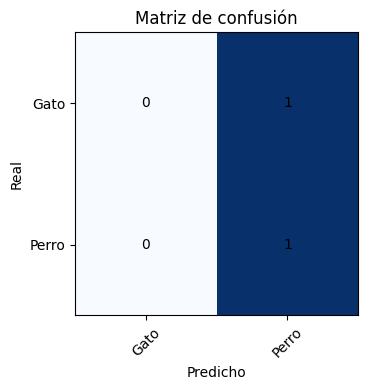

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.40, random_state=42, stratify=y)

clf = LinearSVC(C=1.0, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print("Accuracy (SVM lineal):", f"{acc*100:.2f}%")
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

classes = sorted(list(set(y)))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.title("Matriz de confusión")
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center')

plt.xlabel("Predicho"); plt.ylabel("Real")
plt.tight_layout(); plt.show()
